## 343 - Computing and Plotting Frontogenesis

[Youtube](https://www.youtube.com/watch?v=xs7nnIG8M-s)

In [1]:
from datetime import datetime

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import metpy.calc as mpcalc
import numpy as np
import xarray as xr

from herbie import Herbie
from metpy.units import units

In [2]:
date = datetime(2023, 4, 20, 12)
H = Herbie(date, model='hrrr', product='prs', fxx=0)
ds = H.xarray(':(TMP|UGRD|VGRD):850 mb')
ds

✅ Found ┊ model=hrrr ┊ product=prs ┊ 2023-Apr-20 12:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local


c:\Users\jessi\miniforge3\envs\metpy\Lib\site-packages\herbie\core.py:978: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  logic = df.search_this.str.contains(search)
c:\Users\jessi\miniforge3\envs\metpy\Lib\site-packages\cfgrib\xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([o, ds], **kwargs)
c:\Users\jessi\miniforge3\envs\metpy\Lib\site-packages\cfgrib\xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different r

<xarray.Dataset> Size: 53MB
Dimensions:              (y: 1059, x: 1799)
Coordinates:
    latitude             (y, x) float64 15MB 21.14 21.15 21.15 ... 47.85 47.84
    longitude            (y, x) float64 15MB 237.3 237.3 237.3 ... 299.0 299.1
    time                 datetime64[ns] 8B 2023-04-20T12:00:00
    step                 timedelta64[ns] 8B 00:00:00
    isobaricInhPa        float64 8B 850.0
    valid_time           datetime64[ns] 8B 2023-04-20T12:00:00
    gribfile_projection  object 8B None
Dimensions without coordinates: y, x
Data variables:
    t                    (y, x) float32 8MB 289.8 289.8 289.8 ... 269.8 269.9
    u                    (y, x) float32 8MB -5.092 -5.155 ... 0.2203 0.03278
    v                    (y, x) float32 8MB -2.495 -2.495 ... -4.245 -4.057
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    model:                   hrrr
    product:                 prs
    description:             High-Resolution Rapid Refresh - CONUS
    remote_grib:             https://noaa-hrrr-bdp-pds.s3.amazonaws.com/hrrr....
    local_grib:              C:\Users\jessi\data\hrrr\20230420\subset_cfef034...
    search:                  :(TMP|UGRD|VGRD):850 mb

In [3]:
ds = ds.metpy.parse_cf()
ds

<xarray.Dataset> Size: 53MB
Dimensions:              (y: 1059, x: 1799)
Coordinates:
    latitude             (y, x) float64 15MB 21.14 21.15 21.15 ... 47.85 47.84
    longitude            (y, x) float64 15MB 237.3 237.3 237.3 ... 299.0 299.1
    time                 datetime64[ns] 8B 2023-04-20T12:00:00
    step                 timedelta64[ns] 8B 00:00:00
    isobaricInhPa        float64 8B 850.0
    valid_time           datetime64[ns] 8B 2023-04-20T12:00:00
    gribfile_projection  object 8B None
    metpy_crs            object 8B Projection: lambert_conformal_conic
Dimensions without coordinates: y, x
Data variables:
    t                    (y, x) float32 8MB 289.8 289.8 289.8 ... 269.8 269.9
    u                    (y, x) float32 8MB -5.092 -5.155 ... 0.2203 0.03278
    v                    (y, x) float32 8MB -2.495 -2.495 ... -4.245 -4.057
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    model:                   hrrr
    product:                 prs
    description:             High-Resolution Rapid Refresh - CONUS
    remote_grib:             https://noaa-hrrr-bdp-pds.s3.amazonaws.com/hrrr....
    local_grib:              C:\Users\jessi\data\hrrr\20230420\subset_cfef034...
    search:                  :(TMP|UGRD|VGRD):850 mb

In [4]:
temperature = ds['t'].metpy.quantify()
u = ds['u'].metpy.quantify()
v = ds['v'].metpy.quantify()
lat = ds['latitude']
lon = ds['longitude']

In [5]:
west = -104
east = -92
south = 31
north = 40

In [6]:
pressure = 850 * units.hPa
theta = mpcalc.potential_temperature(pressure, temperature)

In [7]:
theta

Magnitude,[[303.5808410644531 303.5808410644531 303.5808410644531 ... 302.9261474609375 302.9261474609375 302.9261474609375] [303.5808410644531 303.5808410644531 303.5808410644531 ... 302.9261474609375 302.9261474609375 302.9261474609375] [303.5808410644531 303.5808410644531 303.5808410644531 ... 302.9261474609375 302.9261474609375 302.9261474609375] ... [283.6123046875 283.6123046875 283.6123046875 ... 282.69573974609375 282.7611999511719 282.7611999511719] [283.5468444824219 283.5468444824219 283.6123046875 ... 282.6302490234375 282.69573974609375 282.69573974609375] [283.48138427734375 283.5468444824219 283.6123046875 ... 282.6302490234375 282.6302490234375 282.69573974609375]]
Units,kelvin


In [8]:
dx, dy = mpcalc.lat_lon_grid_deltas(lon, lat)

In [9]:
fronto = mpcalc.frontogenesis(theta, u, v, dx=dx, dy=dy)

C:\Users\jessi\AppData\Local\Temp\ipykernel_38476\3244662397.py:1: UserWarning: More than one time coordinate present for variable .
  fronto = mpcalc.frontogenesis(theta, u, v, dx=dx, dy=dy)


In [10]:
fronto

Magnitude,[[2.7950245051284244e-22 2.58231185216563e-23 1.3142531995929443e-12 ... -3.971872966197577e-22 -3.022040730592239e-24 -4.463115459051605e-22] [3.1784041549882203e-22 4.638896096514715e-25 -5.595657723158829e-23 ... -4.910270356108614e-25 -4.973803748601806e-25 8.7852448720028e-22] [7.615543955642713e-13 7.603965309279337e-13 7.592392050400879e-13 ... 1.3455833348938183e-10 -4.911024023077411e-25 6.351452547433175e-22] ... [7.259960909459168e-10 4.858061950206807e-10 2.4298029412904214e-10 ... 5.089510271327209e-10 3.393498914101251e-10 -1.6231279177007627e-10] [-1.623002056403824e-10 3.4345839859039193e-10 -4.83234053859999e-10 ... 1.6961502529990857e-10 -2.686907185245105e-10 -8.596984642531647e-11] [3.470045409934872e-10 -1.728254096129137e-09 -6.036237639193313e-10 ... 1.685034743008443e-10 -3.76935894878113e-10 2.4302920876117797e-09]]
Units,kelvin/(meter second)


In [11]:
fronto_plot = fronto * 1.08e9

Text(0.0, 1.0, 'HRRR 850-hPa Frontogenesis/Frontolysis, Temperature, and Winds \nValid: 2023-04-20T12:00 UTC')

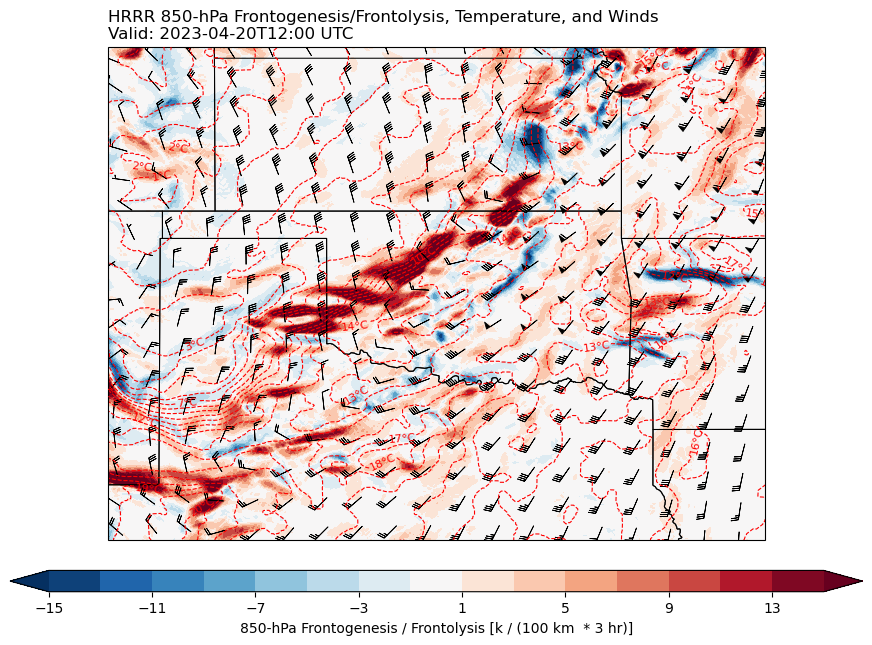

In [12]:
fig = plt.figure(figsize=(11, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent([west, east, south, north], crs=ccrs.PlateCarree())

# Map features
ax.add_feature(cfeature.COASTLINE, linewidth=0.75)
ax.add_feature(cfeature.BORDERS, linewidth=0.75)
ax.add_feature(cfeature.STATES, linewidth=0.75)

# Frontogenesis
fronto_levels = np.arange(-15, 16, 2)
cf = ax.contourf(lon, lat, fronto_plot, levels=fronto_levels, cmap = 'RdBu_r', extend='both', transform=ccrs.PlateCarree())

cbar = plt.colorbar(cf, ax=ax, orientation='horizontal', pad=0.05, aspect=40)
cbar.set_label("850-hPa Frontogenesis / Frontolysis [k / (100 km  * 3 hr)]")

# Temperature contours: thin red dashed lines
temp_levels = np.arange(-4, 40, 1)

cs = ax.contour(lon, lat, temperature.metpy.convert_units('degC'), levels=temp_levels, colors="red", linewidths=0.8, linestyles="dashed", transform=ccrs.PlateCarree())

ax.clabel(cs, inline=True, fontsize=8, fmt="%d°C")

skip = 20
ax.barbs(lon.values[::skip, ::skip], lat.values[::skip, ::skip], u.metpy.convert_units("kt").values[::skip, ::skip], v.metpy.convert_units("kt").values[::skip, ::skip], length=5, linewidth=0.6, transform=ccrs.PlateCarree())

valid_time = np.datetime_as_string(ds.valid_time.values, unit="m")

ax.set_title(f"HRRR 850-hPa Frontogenesis/Frontolysis, Temperature, and Winds \n" 
             f"Valid: {valid_time} UTC", loc="left")